In [1]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn_extra.cluster import KMedoids
from sklearn.decomposition import PCA

from cluster_weather_years.functions import build_df, plot_clim_per_cluster

from cluster_weather_years.constants import NUM_CLUSTERS

In [2]:
# Build NL dataframe
df_daily, df_nl_rolling = build_df()

# 1. Compute mean and standard deviation per year w.r.t. climatology, just for visualisation

In [3]:
clim_means = df_daily.mean(axis=0)

yearly_means = df_daily.groupby(
    [pd.Grouper(level="model"), df_nl_rolling.index.get_level_values("Date").year]
).agg("mean")

# normalize it by the climatological mean, and convert into percentage
yearly_mean_anom_norm = (yearly_means - clim_means) * 100 / clim_means

clim_stds = df_daily.std(axis=0)
yearly_stds = df_daily.groupby(
    [pd.Grouper(level="model"), df_nl_rolling.index.get_level_values("Date").year]
).agg("std")

# normalize it by the climatological std, and convert into percentage
yearly_std_anom_norm = (yearly_stds - clim_stds) * 100 / clim_stds

(-50.0, 50.0)

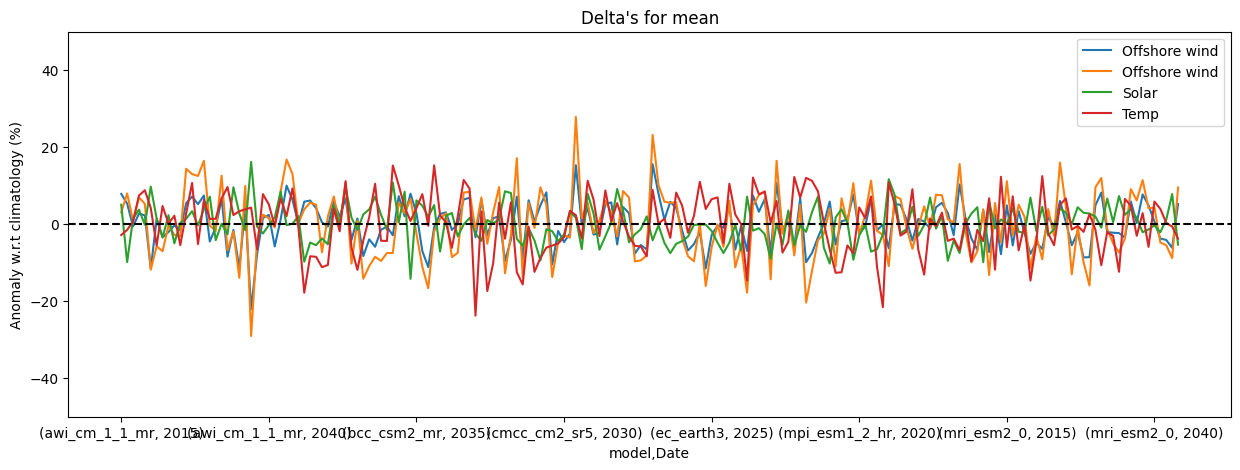

In [4]:
# NOTE: CDD is out of bounds for these plotting ylims.
plt.figure(figsize=(15, 5))
yearly_mean_anom_norm["NL_OFF"].plot(label="Offshore wind")
yearly_mean_anom_norm["NL_ON"].plot(label="Offshore wind")
yearly_mean_anom_norm["NL_SOLAR"].plot(label="Solar")
yearly_mean_anom_norm["NL_TEMP"].plot(label="Temp")
plt.axhline(y=0, c="k", linestyle="--")
# yearly_mean_anom_norm["CDD"].plot(label="CDD")
# yearly_mean_anom_norm["HDD"].plot(label="HDD")

plt.legend()
plt.ylabel("Anomaly w.r.t climatology (%)")
plt.title("Delta's for mean")
plt.ylim(-50, 50)

(-50.0, 50.0)

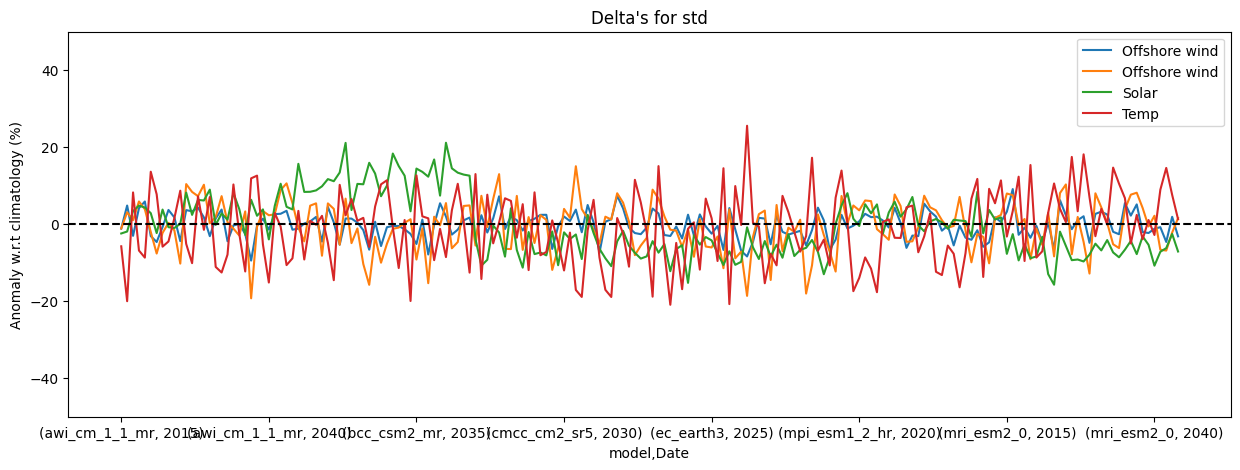

In [5]:
plt.figure(figsize=(15, 5))

yearly_std_anom_norm["NL_OFF"].plot(label="Offshore wind")
yearly_std_anom_norm["NL_ON"].plot(label="Offshore wind")
yearly_std_anom_norm["NL_SOLAR"].plot(label="Solar")
yearly_std_anom_norm["NL_TEMP"].plot(label="Temp")
plt.axhline(y=0, c="k", linestyle="--")

# yearly_std_anom_norm["CDD"].plot(label="CDD")
# yearly_std_anom_norm["HDD"].plot(label="HDD")


plt.legend(loc="upper right")
plt.ylabel("Anomaly w.r.t climatology (%)")
plt.title("Delta's for std")
plt.ylim(-50, 50)

# 2. Perform K-Medoids clustering

In [6]:
# standardize the data to mean = 0, std = 1
df_standardize = df_daily[["NL_OFF", "NL_ON", "NL_SOLAR", "NL_TEMP"]]

scaler = StandardScaler()
df_standardized = pd.DataFrame(
    scaler.fit_transform(df_standardize),
    columns=df_standardize.columns,
    index=df_daily.index,
)

In [7]:
yearly_stats = df_standardized.groupby(
    [pd.Grouper(level="model"), df_nl_rolling.index.get_level_values("Date").year]
).agg(["mean", "var"])

yearly_stats.columns = [f"{col}_{stat}" for col, stat in yearly_stats.columns]

# scale the year‑level feature matrix
X = StandardScaler().fit_transform(yearly_stats)

In [8]:
# perform K-Medoids clustering

kmed = KMedoids(n_clusters=NUM_CLUSTERS).fit(X)
yearly_stats["cluster_med"] = kmed.labels_

pca = PCA(n_components=2, random_state=0)
X_pca = pca.fit_transform(X)  # (n_years, 2)
centers_pca = pca.transform(kmed.cluster_centers_)  # (k, 2)

# 3. Visualize clusters, using PCA-projection

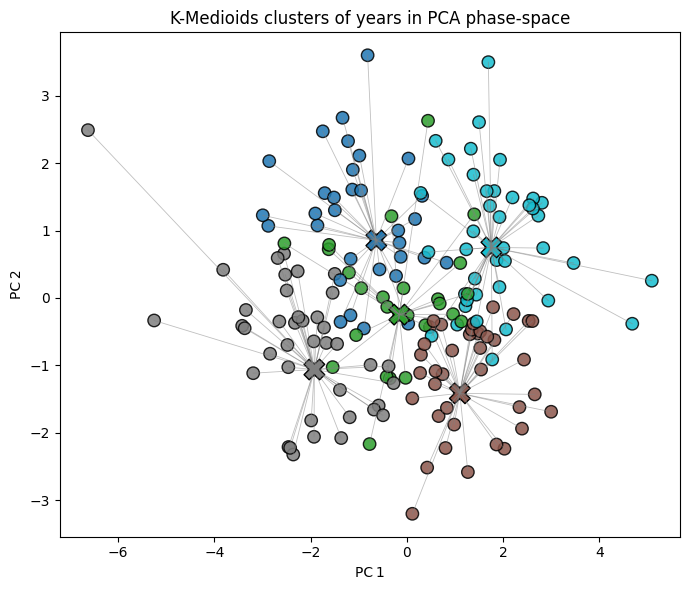

In [9]:
fig, ax = plt.subplots(figsize=(7, 6))

# years as coloured dots
pts = ax.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=kmed.labels_,
    cmap="tab10",
    s=80,
    alpha=0.85,
    edgecolor="k",
)

# lines to centroids (distance visualisation)
for i, (x, y) in enumerate(X_pca):
    cx, cy = centers_pca[kmed.labels_[i]]
    ax.plot([x, cx], [y, cy], lw=0.6, color="grey", alpha=0.5)

# centroids as large X‑markers
ax.scatter(
    centers_pca[:, 0],
    centers_pca[:, 1],
    marker="X",
    c=range(len(centers_pca)),
    cmap="tab10",
    s=220,
    edgecolor="k",
)

ax.set_xlabel("PC 1")
ax.set_ylabel("PC 2")
ax.set_title("K-Medioids clusters of years in PCA phase‑space")
plt.tight_layout()
plt.show()

In [10]:
loadings = pd.DataFrame(
    pca.components_.T,  # shape (n_feats, n_components)
    index=yearly_stats.columns[:-1],  # drop 'cluster'
    columns=["PC1", "PC2"],
).round(3)

print("PCA loadings (coefficients):")
print(loadings)
print("\nExplained variance ratio:", pca.explained_variance_ratio_.round(3))

PCA loadings (coefficients):
                 PC1    PC2
NL_OFF_mean    0.464 -0.132
NL_OFF_var     0.363  0.269
NL_ON_mean     0.504 -0.047
NL_ON_var      0.481  0.177
NL_SOLAR_mean -0.152  0.646
NL_SOLAR_var   0.015  0.468
NL_TEMP_mean   0.109  0.465
NL_TEMP_var   -0.364  0.158

Explained variance ratio: [0.434 0.208]


# 4. Analyze centroids

In [ ]:
indices = kmed.medoid_indices_
centroid_years = yearly_mean_anom_norm.iloc[indices]
centroid_years

NL_OFF     NL_ON  NL_SOLAR   NL_TEMP         CDD  \
model         Date                                                       
cmcc_cm2_sr5  2035 -2.747994 -2.357555  2.741770  6.329687 -100.000000   
mpi_esm1_2_hr 2038  1.417139 -1.926181  0.150819  1.526962  -18.458030   
cmcc_cm2_sr5  2041  2.868697  6.898325 -4.725279 -3.194305 -100.000000   
              2043 -5.440838 -9.439953 -1.333746 -5.821347 -100.000000   
              2040  4.410240  8.573233  3.467580  0.637443   17.712294   

                          HDD  
model         Date             
cmcc_cm2_sr5  2035  -1.183396  
mpi_esm1_2_hr 2038 -10.696593  
cmcc_cm2_sr5  2041   0.903975  
              2043  15.765865  
              2040  -3.290229

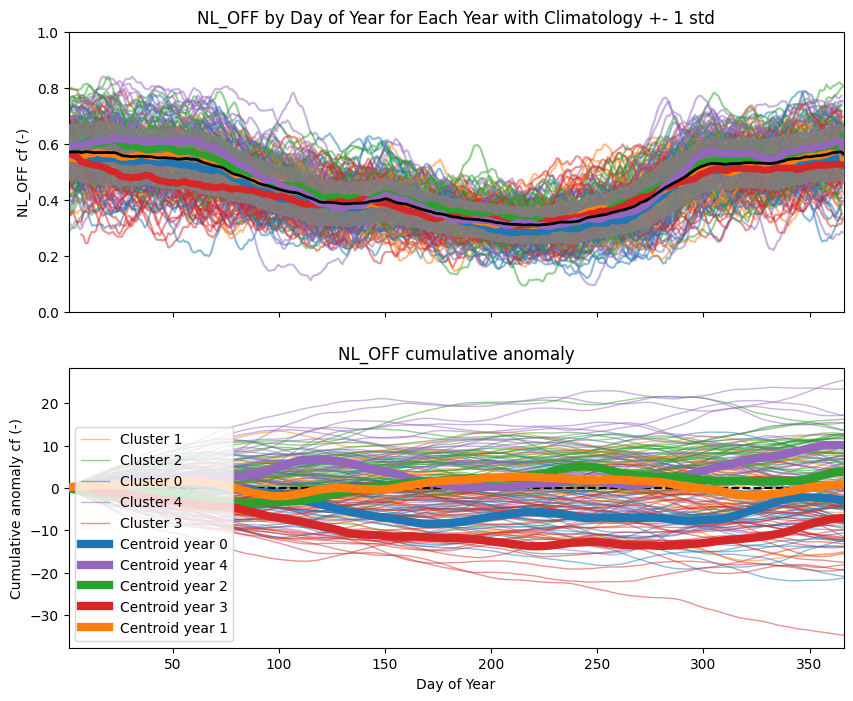

In [12]:
plot_clim_per_cluster(df_nl_rolling, yearly_stats, centroid_years, "NL_OFF")

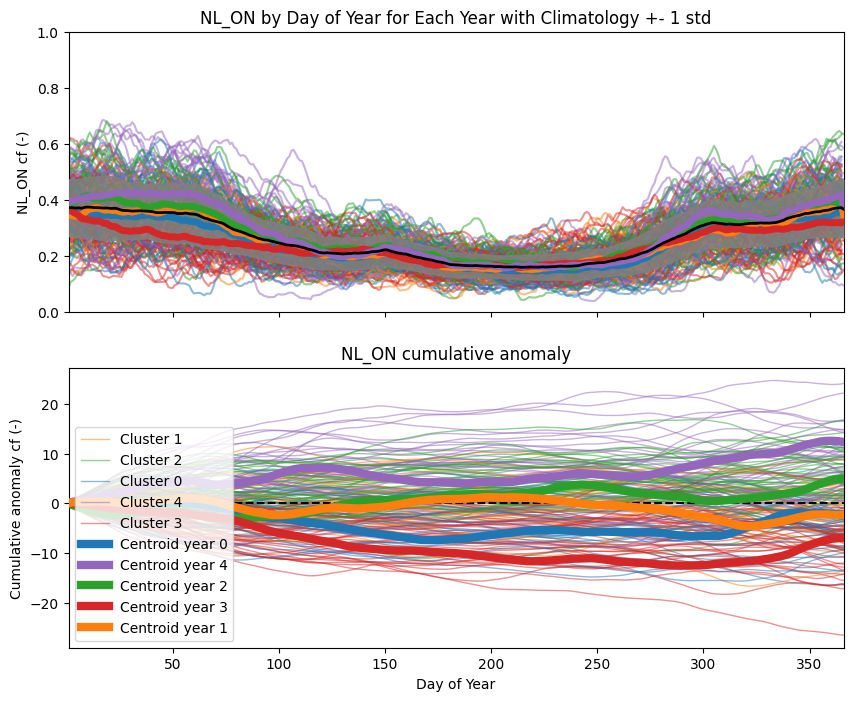

In [13]:
plot_clim_per_cluster(df_nl_rolling, yearly_stats, centroid_years, "NL_ON")

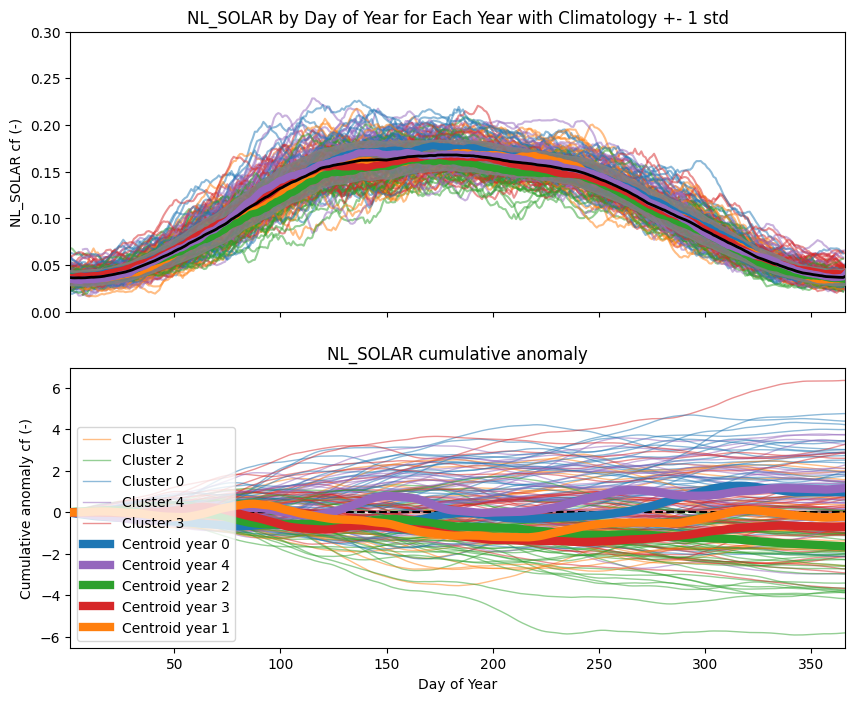

In [14]:
plot_clim_per_cluster(df_nl_rolling, yearly_stats, centroid_years, "NL_SOLAR")

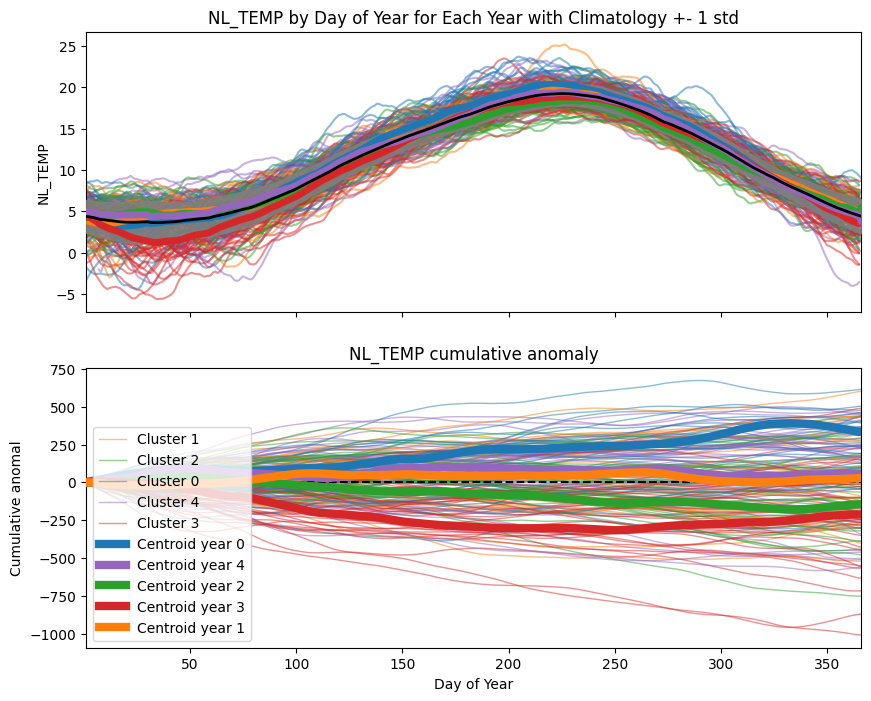

In [15]:
plot_clim_per_cluster(df_nl_rolling, yearly_stats, centroid_years, "NL_TEMP")